# 03 – Module 1: Traffic Volume Prediction (Regression)
**Goal:** predict `traffic_volume` (vehicles per hour) from time and weather features.

**Success criteria (set before modelling):** R² ≥ 0.90 on the unseen test year and MAE clearly
lower than the baseline.

**Strategy**
* **Time-based split:** train = Oct 2012 – Sep 2017, test = Oct 2017 – Sep 2018 (future data).
* **Hyperparameter tuning:** `GridSearchCV` with 3-fold `TimeSeriesSplit` on the training part only.
* **No data leakage:** scaling/encoding are inside a `Pipeline`, so they are learned from training folds only.
* **Metrics:** MAE, RMSE, R².

In [1]:
import sys, json, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import data_preprocessing as dp
import model_utils as mu

sns.set_theme(style="whitegrid")
IMG = "../Images/"

df = dp.load_clean_featured()
X_train, X_test, y_train, y_test, train_df, test_df = mu.time_split(df, "traffic_volume")
print("Train:", X_train.shape, train_df["date_time"].min().date(), "->", train_df["date_time"].max().date())
print("Test :", X_test.shape, test_df["date_time"].min().date(), "->", test_df["date_time"].max().date())
print("Features used:", dp.FEATURES)

Train: (31831, 14) 2012-10-02 -> 2017-09-30
Test : (8733, 14) 2017-10-01 -> 2018-09-30
Features used: ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hour_sin', 'hour_cos', 'hour', 'day_of_week', 'month', 'weather_main', 'daytype_hour', 'is_weekend', 'is_holiday', 'is_rush_hour']


## 1. Define models and hyperparameter grids
| Model | Why we try it | Tuned hyperparameters |
|---|---|---|
| Baseline (mean) | Minimum bar – always predicts the average | – |
| Linear Regression | Simplest model, Multiple Linear Regression on all features | – |
| Polynomial Regression (deg 2/3) | Curved relationships for numeric features | degree, alpha |
| Ridge (L2) | Shrinks coefficients, handles many one-hot columns | alpha |
| Lasso (L1) | Can set useless coefficients to 0 (feature selection) | alpha |
| Elastic Net | Mix of L1 + L2 | alpha, l1_ratio |
| Decision Tree | Non-linear, learns if-else rules | max_depth, min_samples_leaf |
| Random Forest | Many trees averaged → less overfitting | n_estimators, max_depth, min_samples_leaf |

In [2]:
def make_pipe(model):
    """Preprocessing + model in one object."""
    return Pipeline([("prep", mu.build_preprocessor()), ("model", model)])

# Polynomial regression: polynomial terms of numeric features + one-hot of categorical features
poly_prep = ColumnTransformer([
    ("num", Pipeline([("poly", PolynomialFeatures(include_bias=False)), ("scale", StandardScaler())]),
     dp.NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), dp.CATEGORICAL_FEATURES),
    ("bin", "passthrough", dp.BINARY_FEATURES),
])

models = {
    "Baseline (Mean)": (make_pipe(DummyRegressor(strategy="mean")), {}),
    "Linear Regression": (make_pipe(LinearRegression()), {}),
    "Polynomial Regression": (Pipeline([("prep", poly_prep), ("model", Ridge())]),
                              {"prep__num__poly__degree": [2, 3], "model__alpha": [0.1, 1, 10]}),
    "Ridge": (make_pipe(Ridge()), {"model__alpha": [0.1, 1, 10, 100]}),
    "Lasso": (make_pipe(Lasso(max_iter=5000)), {"model__alpha": [0.1, 1, 10]}),
    "Elastic Net": (make_pipe(ElasticNet(max_iter=5000)),
                    {"model__alpha": [0.01, 0.1, 1], "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "Decision Tree": (make_pipe(DecisionTreeRegressor(random_state=mu.RANDOM_STATE)),
                      {"model__max_depth": [4, 6, 8, 10, 12], "model__min_samples_leaf": [1, 5, 20]}),
    "Random Forest": (make_pipe(RandomForestRegressor(n_estimators=150, random_state=mu.RANDOM_STATE, n_jobs=-1)),
                      {"model__max_depth": [8, 10, 12], "model__min_samples_leaf": [5, 20]}),
}

## 2. Train, tune (time-series CV) and evaluate on the test year

In [3]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

results, fitted, best_params = [], {}, {}
for name, (pipe, grid) in models.items():
    start = time.time()
    # GridSearchCV tries every combination in the grid using TimeSeriesSplit CV
    search = GridSearchCV(pipe, grid or {}, cv=mu.CV, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_                 # refitted on ALL training data with best params
    test_pred = best.predict(X_test)
    row = {"Model": name, "CV_RMSE": -search.best_score_, **regression_metrics(y_test, test_pred),
           "Train_R2": r2_score(y_train, best.predict(X_train)), "Time_s": time.time() - start}
    results.append(row)
    fitted[name] = best
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:22s} CV-RMSE={row['CV_RMSE']:7.1f}  Test MAE={row['MAE']:6.1f}  "
          f"RMSE={row['RMSE']:6.1f}  R2={row['R2']:.3f}  best={best_params[name]}")

Baseline (Mean)        CV-RMSE= 1970.6  Test MAE=1733.3  RMSE=1977.8  R2=-0.000  best={}


Linear Regression      CV-RMSE=  485.6  Test MAE= 295.1  RMSE= 459.3  R2=0.946  best={}


Polynomial Regression  CV-RMSE=  485.2  Test MAE= 288.2  RMSE= 452.5  R2=0.948  best={'alpha': 10, 'prep__num__poly__degree': 3}


Ridge                  CV-RMSE=  485.1  Test MAE= 296.0  RMSE= 459.3  R2=0.946  best={'alpha': 10}


Lasso                  CV-RMSE=  485.4  Test MAE= 295.2  RMSE= 459.3  R2=0.946  best={'alpha': 0.1}


Elastic Net            CV-RMSE=  486.6  Test MAE= 303.1  RMSE= 461.7  R2=0.945  best={'alpha': 0.01, 'l1_ratio': 0.8}


Decision Tree          CV-RMSE=  471.1  Test MAE= 251.5  RMSE= 418.5  R2=0.955  best={'max_depth': 10, 'min_samples_leaf': 5}


Random Forest          CV-RMSE=  442.7  Test MAE= 234.9  RMSE= 395.0  R2=0.960  best={'max_depth': 12, 'min_samples_leaf': 5}


## 3. Model comparison

In [4]:
res = pd.DataFrame(results).set_index("Model").round(3)
res.to_csv("../Reports/regression_results.csv")
res

,CV_RMSE,MAE,RMSE,R2,Train_R2,Time_s
Model,,,,,,
Baseline (Mean),1970.630,1733.315,1977.830,-0.000,0.000,14.902
Linear Regression,485.586,295.106,459.325,0.946,0.945,11.163
Polynomial Regression,485.236,288.181,452.490,0.948,0.946,6.123
Ridge,485.081,296.045,459.309,0.946,0.945,2.818
Lasso,485.352,295.208,459.325,0.946,0.945,42.837
Elastic Net,486.624,303.077,461.709,0.945,0.944,18.749
Decision Tree,471.129,251.502,418.493,0.955,0.962,12.370
Random Forest,442.742,234.919,394.969,0.960,0.969,223.455


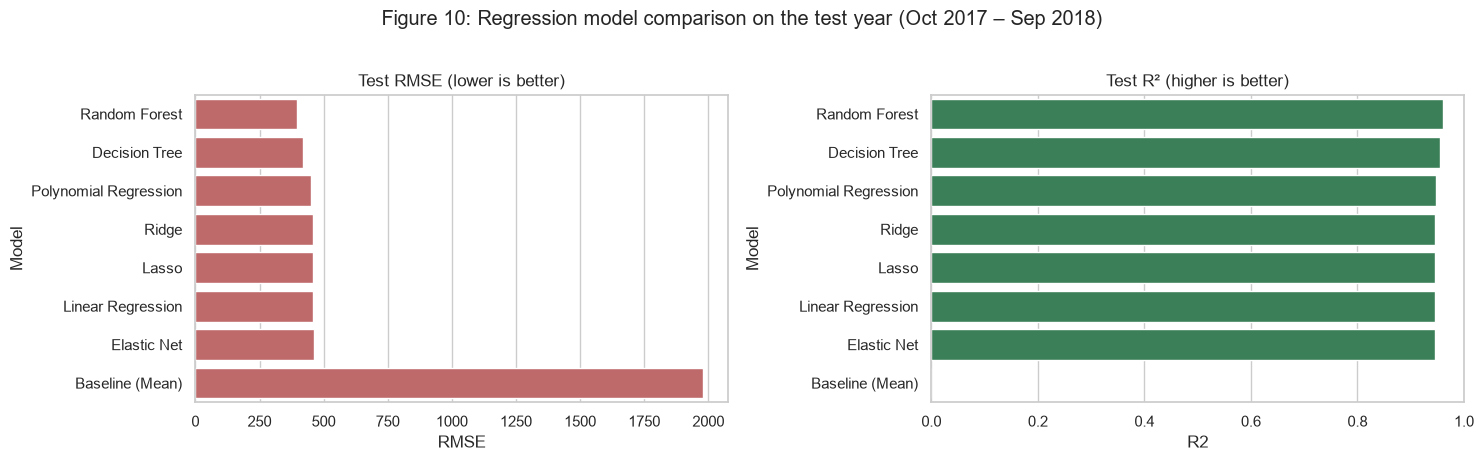

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = res.sort_values("RMSE").index
sns.barplot(x=res.loc[order, "RMSE"], y=order, ax=axes[0], color="indianred")
axes[0].set_title("Test RMSE (lower is better)")
sns.barplot(x=res.loc[order, "R2"].clip(lower=0), y=order, ax=axes[1], color="seagreen")
axes[1].set_title("Test R² (higher is better)")
axes[1].set_xlim(0, 1)
plt.suptitle("Figure 10: Regression model comparison on the test year (Oct 2017 – Sep 2018)", y=1.02)
plt.tight_layout()
plt.savefig(IMG + "03_regression_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation of the comparison**
* The **baseline** (always predicting the mean ≈ 3290) has R² = 0 and MAE ≈ 1733 – every model beats it by far.
* **Linear, Ridge, Lasso, Elastic Net** all reach R² ≈ 0.946. They work well **because of feature
  engineering**: one-hot `hour` and the `daytype_hour` interaction let a linear model learn a different
  value for each hour on working days vs off days. Regularisation (Ridge/Lasso) gives almost no gain,
  because with ~32,000 rows and ~110 columns the plain linear model is not overfitting
  (Train R² ≈ Test R²).
* **Polynomial regression** (degree 3 on numeric features) improves slightly (R² 0.948) – curved effects
  of temperature/hour help a little.
* **Decision Tree** (depth 10) and **Random Forest** (depth 12) capture non-linear interactions
  (e.g. weather × hour) and are best. Random Forest averages 150 trees, which lowers variance:
  **MAE ≈ 235 vehicles/h, RMSE ≈ 395, R² ≈ 0.960** on the unseen year.
* Train R² (0.969) is only a little higher than test R² (0.960) → **no serious overfitting**.
* ✅ Success criterion (R² ≥ 0.90, MAE far below baseline) is met.

**Final model choice: Random Forest** – lowest CV-RMSE *and* lowest test error. Cost: it is slower to
train (~5 min with tuning) and less interpretable than linear regression.

## 4. Best model – detailed evaluation

Best model: Random Forest {'max_depth': 12, 'min_samples_leaf': 5}
{'MAE': 234.91929840195164, 'RMSE': np.float64(394.96924099737214), 'R2': 0.9601033519947527}


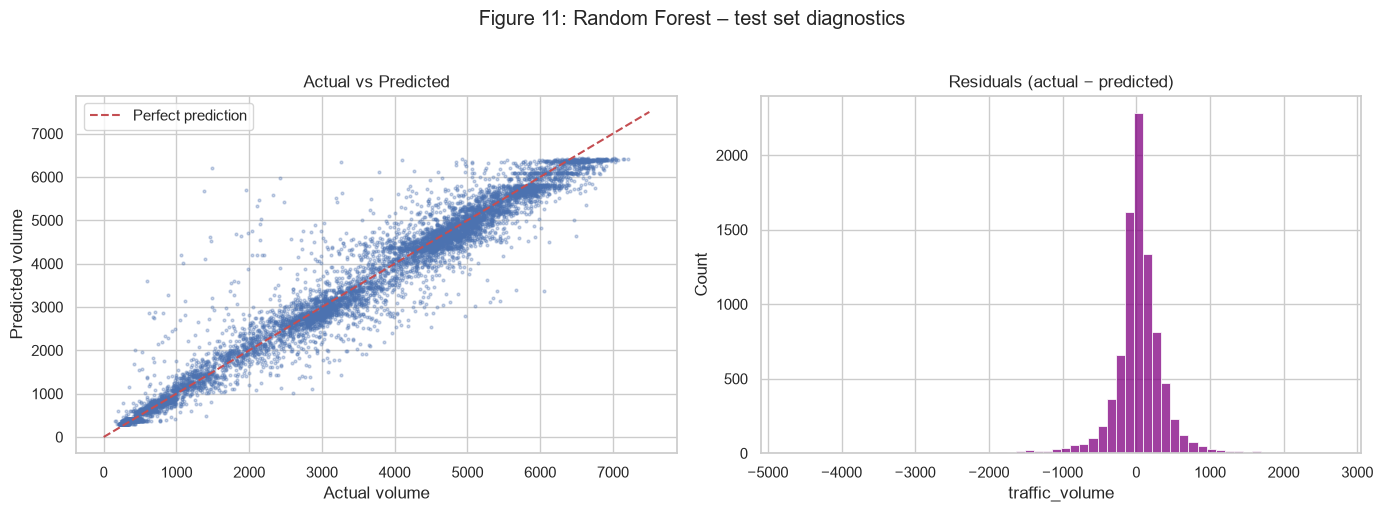

In [6]:
best_name = res["RMSE"].idxmin()
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
print("Best model:", best_name, best_params[best_name])
print(regression_metrics(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred, s=4, alpha=0.3)
axes[0].plot([0, 7500], [0, 7500], "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual volume"); axes[0].set_ylabel("Predicted volume")
axes[0].set_title("Actual vs Predicted"); axes[0].legend()
residuals = y_test - y_pred
sns.histplot(residuals, bins=60, ax=axes[1], color="purple")
axes[1].set_title("Residuals (actual − predicted)")
plt.suptitle(f"Figure 11: {best_name} – test set diagnostics", y=1.02)
plt.tight_layout()
plt.savefig(IMG + "03_best_regressor_diagnostics.png", dpi=120, bbox_inches="tight")
plt.show()

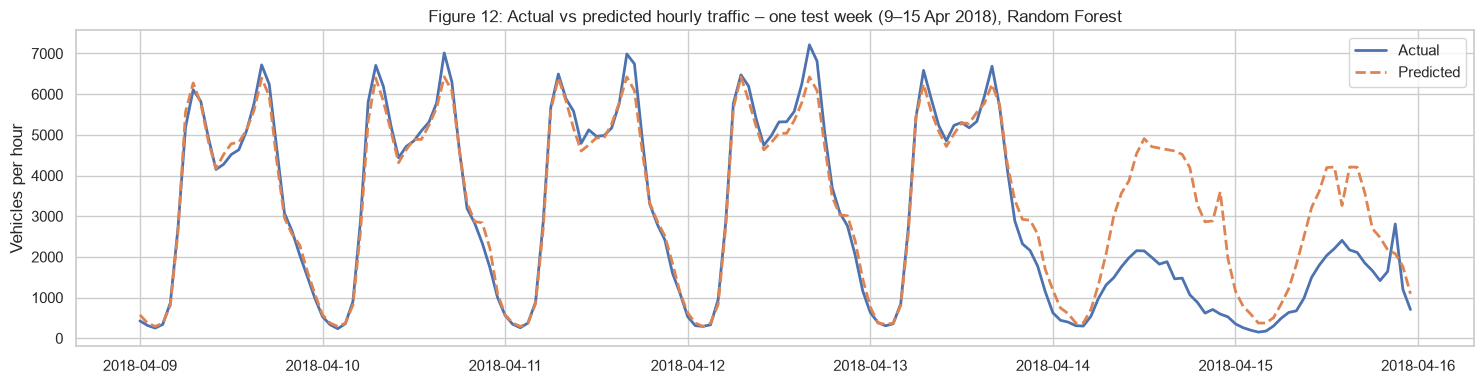

In [7]:
# One week of real vs predicted traffic
week = test_df.assign(pred=y_pred).set_index("date_time").loc["2018-04-09":"2018-04-15"]
plt.figure(figsize=(15, 4))
plt.plot(week.index, week["traffic_volume"], label="Actual", lw=2)
plt.plot(week.index, week["pred"], label="Predicted", lw=2, ls="--")
plt.title(f"Figure 12: Actual vs predicted hourly traffic – one test week (9–15 Apr 2018), {best_name}")
plt.ylabel("Vehicles per hour"); plt.legend()
plt.tight_layout()
plt.savefig(IMG + "03_week_prediction.png", dpi=120)
plt.show()

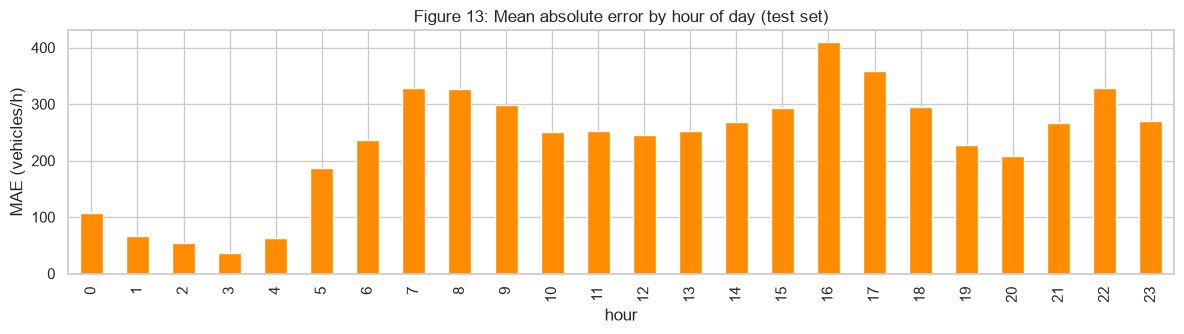

In [8]:
# Where does the model make the biggest errors? (error by hour of day)
err = test_df.assign(abs_err=np.abs(residuals.values)).groupby("hour")["abs_err"].mean()
err.plot(kind="bar", figsize=(12, 3.5), color="darkorange")
plt.title("Figure 13: Mean absolute error by hour of day (test set)")
plt.ylabel("MAE (vehicles/h)")
plt.tight_layout()
plt.savefig(IMG + "03_error_by_hour.png", dpi=120)
plt.show()

## 5. Feature importance (permutation importance on the test set)
Permutation importance = shuffle one feature and measure how much the error increases.
Bigger increase → the model relies more on that feature. It works for any model.

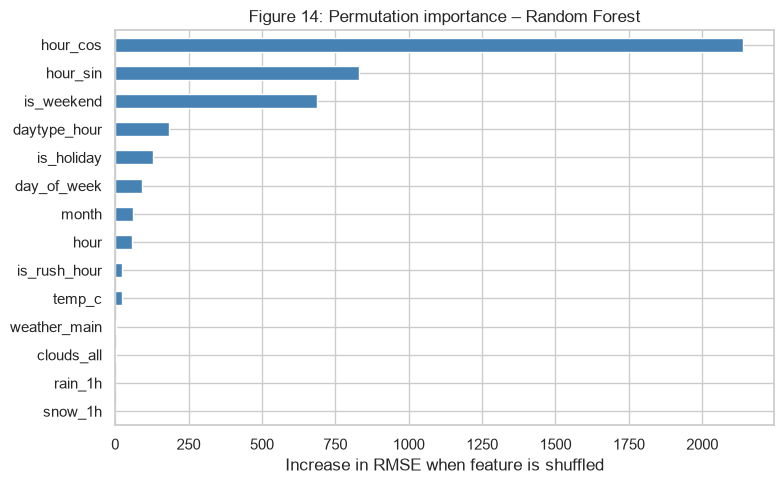

hour_cos        2137.5
hour_sin         829.3
is_weekend       687.4
daytype_hour     182.5
is_holiday       128.0
day_of_week       92.6
month             61.9
hour              56.4
is_rush_hour      24.3
temp_c            23.9
weather_main       2.9
clouds_all         1.2
rain_1h            0.4
snow_1h            0.0
dtype: float64

In [9]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=mu.RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title(f"Figure 14: Permutation importance – {best_name}")
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.tight_layout()
plt.savefig(IMG + "03_feature_importance.png", dpi=120)
plt.show()
imp.sort_values(ascending=False).round(1)

In [10]:
# Lasso coefficients: which one-hot columns did L1 regularisation switch off?
lasso = fitted["Lasso"]
names = lasso.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.named_steps["model"].coef_, index=names)
print(f"Lasso set {(coef == 0).sum()} of {len(coef)} coefficients exactly to zero")

Lasso set 33 of 110 coefficients exactly to zero


**Interpretation of diagnostics and importance**
* Points in the actual-vs-predicted plot lie close to the red line; residuals are centred at 0.
* The one-week plot shows the model reproduces the weekday double peak and the quieter weekend.
* Errors are **largest during rush hours and in the transition hours**, where small timing shifts
  (an accident, roadworks, an event) change volume a lot – information the model does not have.
* **Time features dominate**: `hour_cos`, `hour_sin`, `is_weekend`, `daytype_hour`, `is_holiday`.
  Weather features (`rain_1h`, `snow_1h`, `clouds_all`, `weather_main`) add very little – this agrees with
  the EDA (weak correlation, small ANOVA effect).
* Lasso switched 33 of 110 encoded columns to exactly 0 – automatic feature selection.

**Limitations:** no data on accidents, roadworks or events; a 2014–2015 data gap; only one road (I-94
westbound) so results may not transfer to other cities; the model uses no recent-lag traffic values.

In [11]:
joblib.dump(best_model, "../models/regressor.joblib")
with open("../models/best_params_regression.json", "w") as f:
    json.dump({"best_model": best_name, "params": best_params}, f, indent=2, default=str)
print("Saved models/regressor.joblib")

Saved models/regressor.joblib
